<a href="https://colab.research.google.com/github/DivakarShenoy/Machine-Learning-Portfolio-Divakar-Shenoy/blob/main/Divakar_Shenoy_CIFAR_10_GANv1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
import time


In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1589s 9us/step


In [3]:
print(train_images.shape)

(50000, 32, 32, 3)


In [4]:
a=len(train_images) #made a variable for convenience
#(train_images, train_labels), (test_images, test_labels) = datasets.fashion_mnist.load_data()
train_images = train_images[:a]
train_labels = train_labels[:a]
train_images = train_images.astype("float32") #floating point is needed for keras
train_images = (train_images - 127.5) / 127.5 #sets it b/t -1 and 1 for tanh
#flatten CIFAR - 10 labels

train_labels = train_labels.flatten()
test_labels = test_labels.flatten()

print(train_images.shape)
# make labels one-hot representation
train_labels_one_hot = tf.one_hot(train_labels, 10)
test_labels_one_hot = tf.one_hot(test_labels, 10)
train_labels_one_hot = train_labels_one_hot[:a]

print(train_images.shape)

(50000, 32, 32, 3)
(50000, 32, 32, 3)


In [5]:


tf.random.set_seed(42) #for consistency
np.random.seed(42)

print("Data Shape", train_images.shape)
BUFFER_SHAPE = len(train_images)
BATCH_SIZE = 256
train_dataset = tf.data.Dataset.from_tensor_slices(train_images).shuffle(BUFFER_SHAPE).batch(BATCH_SIZE)

latent_dim = 100 #arbitrary choice

def build_generator():
  init = tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.02)
  model = models.Sequential(name="generator") #make the generator sequential
  model.add(layers.Dense(4*4*256, use_bias = False, input_shape=(latent_dim,))) #dense layer withthe size as the latent
  model.add(layers.BatchNormalization()) #recenters data around zero so its faster
  model.add(layers.LeakyReLU()) #good for preventing gradient issues
  model.add(layers.Reshape((4,4,256)))

  model.add(layers.Conv2DTranspose(128, (4,4), strides = (1,1), padding="same", use_bias=False,kernel_initializer=init))
  model.add(layers.BatchNormalization())
  model.add(layers.LeakyReLU())

  model.add(layers.Conv2DTranspose(64, (4, 4), strides=(2, 2), padding="same", use_bias=False,kernel_initializer=init))
  model.add(layers.BatchNormalization())
  model.add(layers.LeakyReLU())

  model.add(layers.Conv2DTranspose(32, (4, 4), strides=(2, 2), padding="same", use_bias=False,kernel_initializer=init))
  model.add(layers.BatchNormalization())
  model.add(layers.LeakyReLU())




  model.add(layers.Conv2DTranspose(3 , (4, 4), strides=(2, 2), padding="same",use_bias=False, activation="tanh")) #changed it from 1 to 3 because it is an RGB channel

  return model

generator = build_generator()
generator.summary()


Data Shape (50000, 32, 32, 3)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4096)           │       409,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 4, 4, 128)      │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 8, 8, 64)       │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 16, 16, 32)     │        32,768 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 32, 32, 3)      │         1,536 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,116,544 (4.26 MB)

 Trainable params: 1,107,904 (4.23 MB)

 Non-trainable params: 8,640 (33.75 KB)

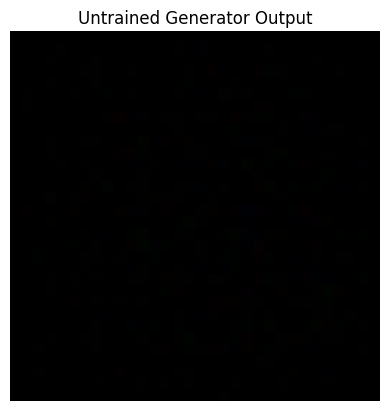

In [6]:
#generate some noise to tets
noise = tf.random.normal([1, latent_dim])
generated_image = generator(noise, training=False)

plt.imshow(generated_image[0,:,:,:]) #: makes it for all the colors
plt.title("Untrained Generator Output")
plt.axis("off")
plt.show()

In [7]:
def build_discriminator():
  init = tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.02)
  modeld = models.Sequential(name="discriminator")
  #modeld.add(layers.Conv)
  modeld.add(layers.Conv2D(32, (4,4), strides=(2,2), padding="same", input_shape=(32,32,3),kernel_initializer=init))
  modeld.add(layers.BatchNormalization())
  modeld.add(layers.LeakyReLU())
  modeld.add(layers.Conv2D(64, (4,4), strides=(2,2), padding="same",kernel_initializer=init))
  modeld.add(layers.BatchNormalization())
  modeld.add(layers.LeakyReLU())
  modeld.add(layers.Conv2D(128, (4,4), strides=(2,2), padding="same",kernel_initializer=init))
  modeld.add(layers.BatchNormalization())
  modeld.add(layers.LeakyReLU())
  modeld.add(layers.Dropout(0.3))


  modeld.add(layers.Flatten())
  modeld.add(layers.Dense(1))
  return modeld
discriminator = build_discriminator()
discriminator.summary()



/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,545 (658.38 KB)

 Trainable params: 168,097 (656.63 KB)

 Non-trainable params: 448 (1.75 KB)

In [8]:
#check if discriminator is working
dec = discriminator(generated_image)
print("Output logit(probability): ", float(dec[0,0]) )
#the low output probability indicates that the discriminator can tell fake photos



Output logit(probability):  -1.6190704627661034e-05


In [9]:
# binary cross entropy for logits, so definietly for this 1 is real, 0 is fake
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
def discriminator_loss(asli_out,nasli_out):
  real_loss = cross_entropy(tf.ones_like(asli_out), asli_out) #difference in probability between the two
  fake_loss = cross_entropy(tf.zeros_like(nasli_out), nasli_out)
  return real_loss + fake_loss
def gen_loss(nasli_out):
  return cross_entropy(tf.ones_like(nasli_out), nasli_out)

generator_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4,beta_1=0.5) #scientific notation
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4,beta_1=0.5) #beta_1 is the exponential decay rate - docummentation says 0.5 is good for stability
#adam does something to speed it up



In [10]:
#training thing
@tf.function
def train_step(images):
  batch_size = tf.shape(images)[0] #first row
  noise = tf.random.normal([batch_size, latent_dim]) #creating noise from the batch size and the latent dimension
  with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True) #created some images

        real_output = discriminator(images, training=True) #real images - discriminator is tested on them
        fake_output = discriminator(generated_images, training=True)#fake images - discriminator is tested on them

        gena_loss = gen_loss(fake_output) #we see the gen_loss for the fake output
        disc_loss = discriminator_loss(real_output, fake_output)# we see how the discriminator peformed on real and fake output

  gradients_of_generator = gen_tape.gradient(gena_loss, generator.trainable_variables)
  gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

  generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables)) #apply the optimizer to the generator
  discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables)) #apply the optimizer to the discriminator

  return gena_loss, disc_loss

In [17]:
#train our generative adversarial network
seed = tf.random.normal([16, latent_dim]) #try changing random state

def generate_and_plot(model, test_input): #we can show every once in a while
    predictions = model(test_input, training=False)
    plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)

        plt.imshow(predictions[i, :, :, :] * 0.5 + 0.5) #dropped cmap = grey for color images added :
        plt.axis("off")
    plt.show()
    print(predictions[0].shape)


Epoch 1/200  gen_loss=4.511  disc_loss=0.170  time=7.5s


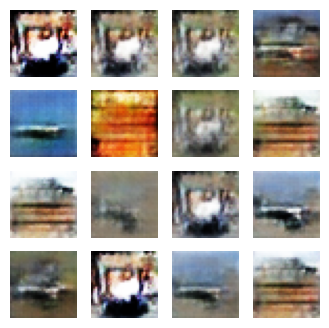

(32, 32, 3)
  Channel stats: Red=0.512/0.233  Green=0.485/0.217  Blue=0.451/0.242  
Epoch 2/200  gen_loss=2.858  disc_loss=0.258  time=6.5s


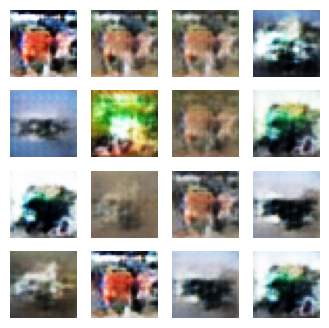

(32, 32, 3)
  Channel stats: Red=0.497/0.262  Green=0.497/0.257  Blue=0.468/0.272  
Epoch 3/200  gen_loss=3.982  disc_loss=0.389  time=6.7s


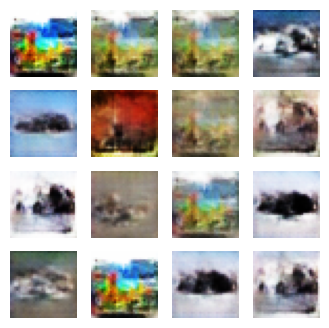

(32, 32, 3)
  Channel stats: Red=0.553/0.241  Green=0.548/0.253  Blue=0.521/0.292  
Epoch 4/200  gen_loss=2.920  disc_loss=0.303  time=6.6s


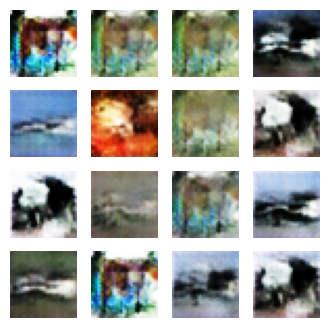

(32, 32, 3)
  Channel stats: Red=0.468/0.255  Green=0.487/0.254  Blue=0.459/0.281  
Epoch 5/200  gen_loss=3.931  disc_loss=0.318  time=6.7s


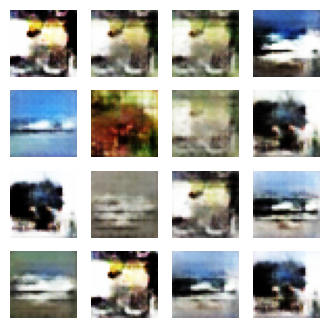

(32, 32, 3)
  Channel stats: Red=0.510/0.293  Green=0.519/0.297  Blue=0.498/0.313  
Epoch 6/200  gen_loss=2.736  disc_loss=0.409  time=6.6s


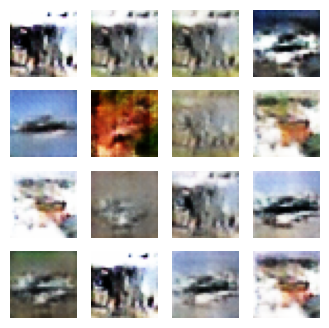

(32, 32, 3)
  Channel stats: Red=0.562/0.255  Green=0.552/0.258  Blue=0.543/0.283  
Epoch 7/200  gen_loss=2.250  disc_loss=0.463  time=6.4s


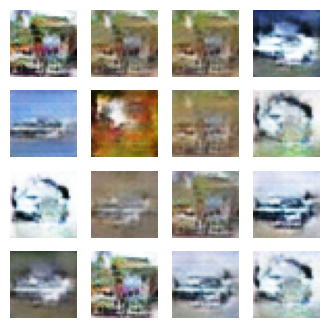

(32, 32, 3)
  Channel stats: Red=0.565/0.202  Green=0.570/0.215  Blue=0.548/0.258  
Epoch 8/200  gen_loss=2.139  disc_loss=0.452  time=6.5s


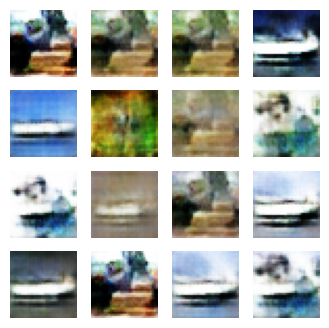

(32, 32, 3)
  Channel stats: Red=0.518/0.277  Green=0.543/0.267  Blue=0.510/0.305  
Epoch 9/200  gen_loss=4.161  disc_loss=0.485  time=6.4s


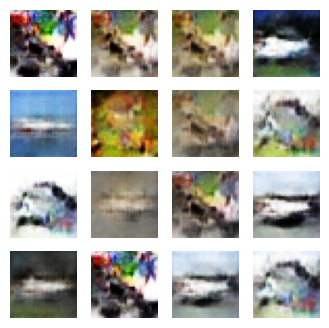

(32, 32, 3)
  Channel stats: Red=0.516/0.250  Green=0.511/0.253  Blue=0.472/0.277  
Epoch 10/200  gen_loss=3.709  disc_loss=0.481  time=6.5s


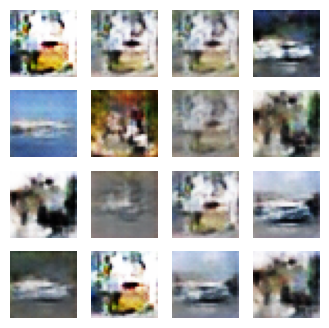

(32, 32, 3)
  Channel stats: Red=0.526/0.247  Green=0.533/0.241  Blue=0.527/0.261  
Epoch 11/200  gen_loss=3.916  disc_loss=0.227  time=6.3s


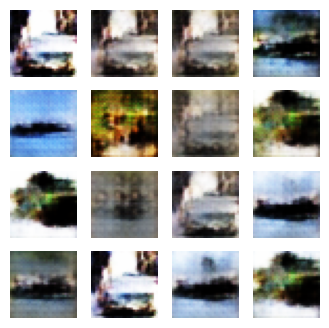

(32, 32, 3)
  Channel stats: Red=0.469/0.288  Green=0.479/0.295  Blue=0.474/0.329  
Epoch 12/200  gen_loss=3.039  disc_loss=0.373  time=6.5s


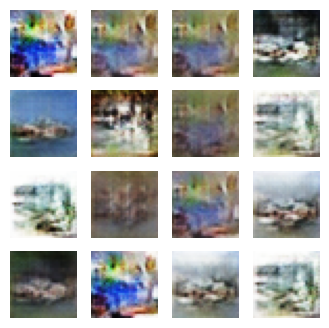

(32, 32, 3)
  Channel stats: Red=0.512/0.221  Green=0.519/0.220  Blue=0.507/0.234  
Epoch 13/200  gen_loss=2.020  disc_loss=0.479  time=6.4s


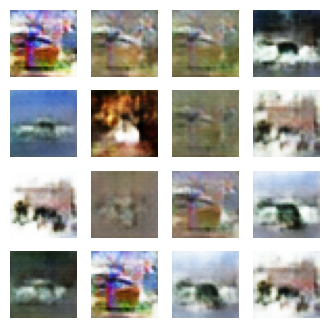

(32, 32, 3)
  Channel stats: Red=0.538/0.226  Green=0.529/0.229  Blue=0.502/0.260  
Epoch 14/200  gen_loss=3.839  disc_loss=0.198  time=6.7s


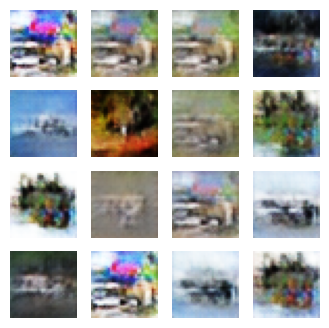

(32, 32, 3)
  Channel stats: Red=0.509/0.230  Green=0.519/0.233  Blue=0.509/0.269  
Epoch 15/200  gen_loss=3.080  disc_loss=0.229  time=6.6s


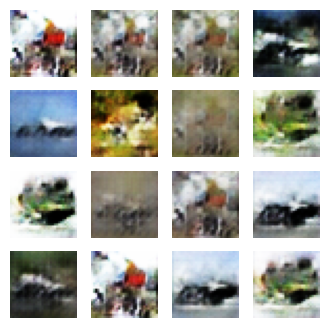

(32, 32, 3)
  Channel stats: Red=0.513/0.258  Green=0.517/0.264  Blue=0.477/0.292  
Epoch 16/200  gen_loss=3.368  disc_loss=0.764  time=6.6s


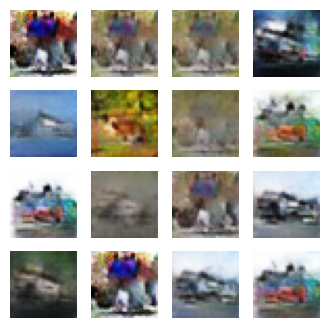

(32, 32, 3)
  Channel stats: Red=0.480/0.218  Green=0.478/0.218  Blue=0.456/0.243  
Epoch 17/200  gen_loss=3.440  disc_loss=0.226  time=10.2s


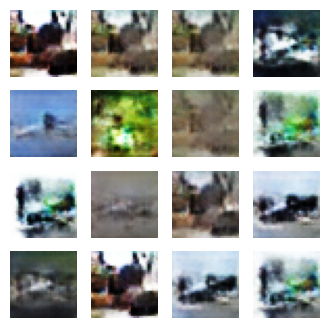

(32, 32, 3)
  Channel stats: Red=0.458/0.246  Green=0.484/0.257  Blue=0.463/0.279  
Epoch 18/200  gen_loss=4.391  disc_loss=0.389  time=6.5s


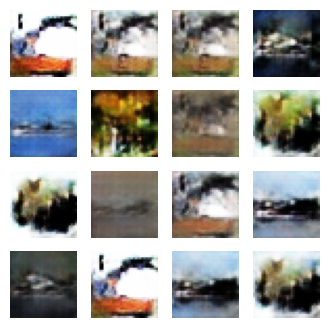

(32, 32, 3)
  Channel stats: Red=0.479/0.285  Green=0.475/0.286  Blue=0.455/0.311  
Epoch 19/200  gen_loss=3.553  disc_loss=0.456  time=6.6s


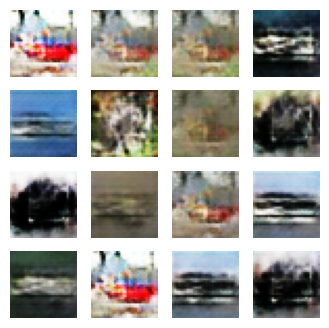

(32, 32, 3)
  Channel stats: Red=0.467/0.265  Green=0.460/0.255  Blue=0.438/0.265  
Epoch 20/200  gen_loss=3.788  disc_loss=0.216  time=6.5s


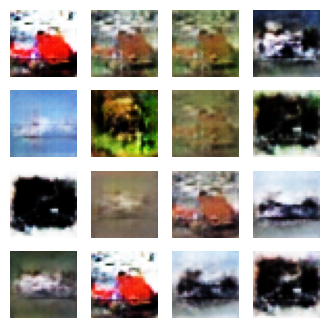

(32, 32, 3)
  Channel stats: Red=0.457/0.285  Green=0.433/0.285  Blue=0.404/0.315  
Epoch 21/200  gen_loss=3.139  disc_loss=0.211  time=6.6s


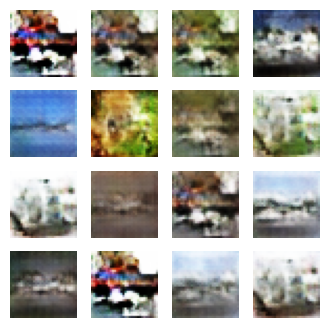

(32, 32, 3)
  Channel stats: Red=0.512/0.253  Green=0.512/0.258  Blue=0.474/0.289  
Epoch 22/200  gen_loss=2.631  disc_loss=0.324  time=6.6s


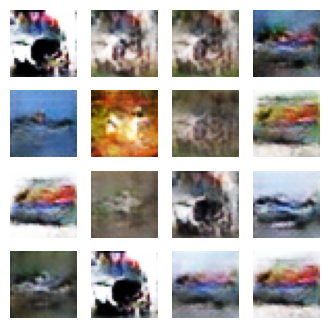

(32, 32, 3)
  Channel stats: Red=0.506/0.261  Green=0.487/0.254  Blue=0.477/0.278  
Epoch 23/200  gen_loss=3.701  disc_loss=0.506  time=6.6s


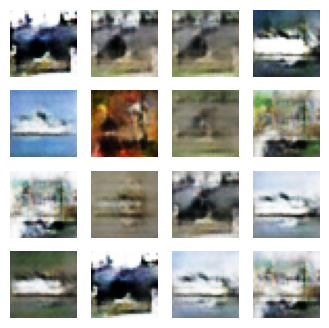

(32, 32, 3)
  Channel stats: Red=0.511/0.247  Green=0.522/0.250  Blue=0.498/0.274  
Epoch 24/200  gen_loss=4.015  disc_loss=0.419  time=6.7s


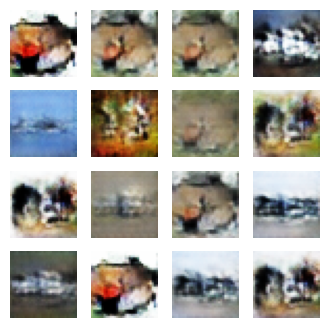

(32, 32, 3)
  Channel stats: Red=0.524/0.241  Green=0.510/0.242  Blue=0.477/0.269  
Epoch 25/200  gen_loss=2.629  disc_loss=0.342  time=6.5s


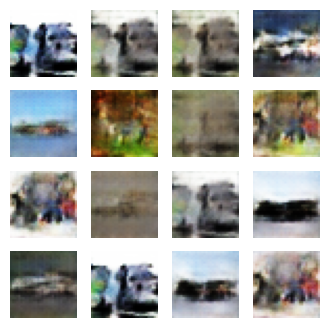

(32, 32, 3)
  Channel stats: Red=0.502/0.246  Green=0.504/0.255  Blue=0.480/0.280  
Epoch 26/200  gen_loss=1.793  disc_loss=0.551  time=6.7s


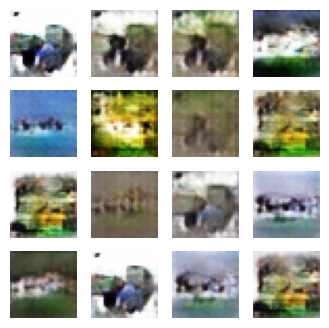

(32, 32, 3)
  Channel stats: Red=0.505/0.244  Green=0.521/0.232  Blue=0.466/0.272  
Epoch 27/200  gen_loss=4.441  disc_loss=0.275  time=6.5s


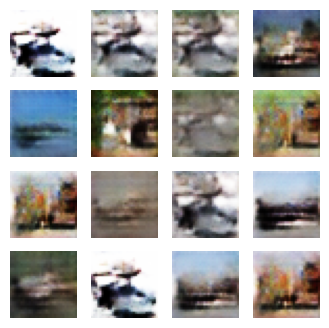

(32, 32, 3)
  Channel stats: Red=0.514/0.250  Green=0.505/0.250  Blue=0.490/0.273  
Epoch 28/200  gen_loss=4.738  disc_loss=0.110  time=6.7s


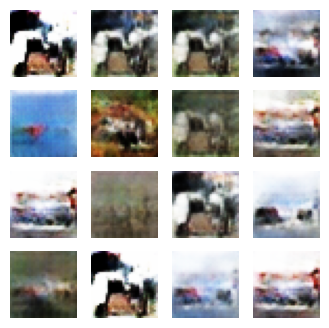

(32, 32, 3)
  Channel stats: Red=0.525/0.288  Green=0.524/0.287  Blue=0.520/0.314  
Epoch 29/200  gen_loss=2.417  disc_loss=0.579  time=6.6s


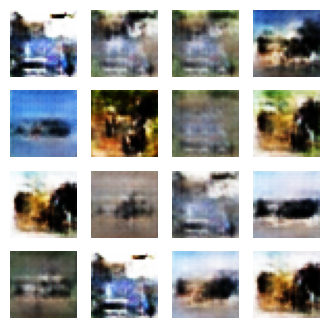

(32, 32, 3)
  Channel stats: Red=0.475/0.272  Green=0.475/0.269  Blue=0.465/0.300  
Epoch 30/200  gen_loss=3.406  disc_loss=0.260  time=6.6s


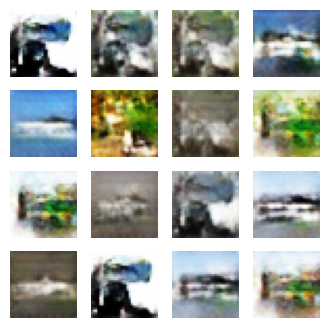

(32, 32, 3)
  Channel stats: Red=0.523/0.258  Green=0.550/0.253  Blue=0.516/0.290  
Epoch 31/200  gen_loss=3.775  disc_loss=0.717  time=6.7s


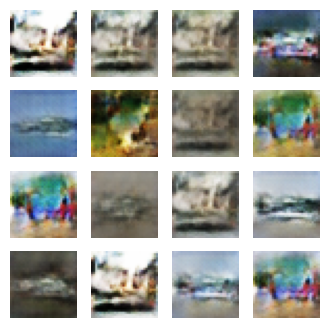

(32, 32, 3)
  Channel stats: Red=0.498/0.217  Green=0.509/0.211  Blue=0.477/0.235  
Epoch 32/200  gen_loss=4.241  disc_loss=0.296  time=6.5s


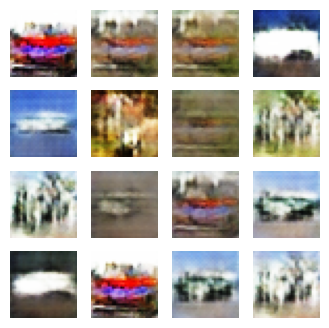

(32, 32, 3)
  Channel stats: Red=0.560/0.238  Green=0.533/0.251  Blue=0.505/0.281  
Epoch 33/200  gen_loss=3.625  disc_loss=0.290  time=6.7s


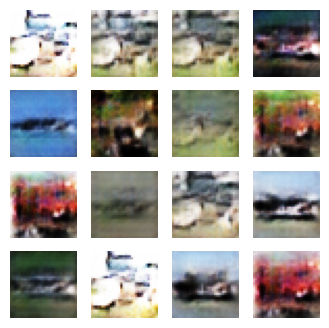

(32, 32, 3)
  Channel stats: Red=0.507/0.267  Green=0.492/0.265  Blue=0.467/0.279  
Epoch 34/200  gen_loss=2.662  disc_loss=0.472  time=6.6s


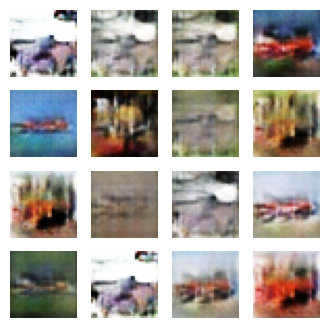

(32, 32, 3)
  Channel stats: Red=0.548/0.238  Green=0.518/0.238  Blue=0.489/0.262  
Epoch 35/200  gen_loss=4.259  disc_loss=0.249  time=6.7s


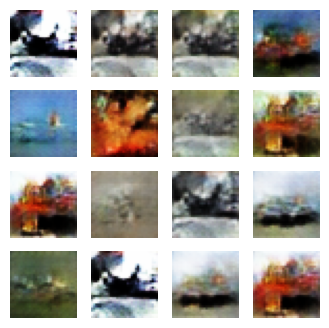

(32, 32, 3)
  Channel stats: Red=0.488/0.258  Green=0.468/0.266  Blue=0.435/0.294  
Epoch 36/200  gen_loss=3.315  disc_loss=0.453  time=6.5s


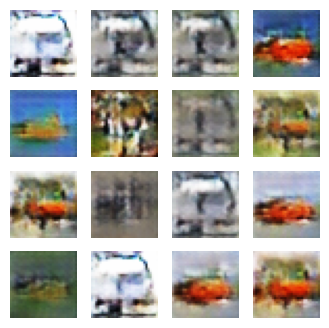

(32, 32, 3)
  Channel stats: Red=0.537/0.223  Green=0.523/0.216  Blue=0.491/0.254  
Epoch 37/200  gen_loss=3.282  disc_loss=0.466  time=6.7s


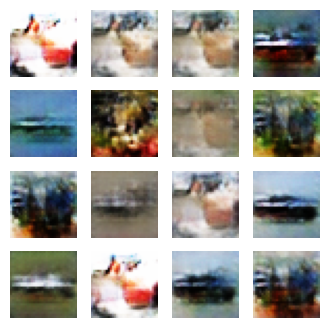

(32, 32, 3)
  Channel stats: Red=0.501/0.268  Green=0.494/0.258  Blue=0.467/0.281  
Epoch 38/200  gen_loss=4.993  disc_loss=0.669  time=6.6s


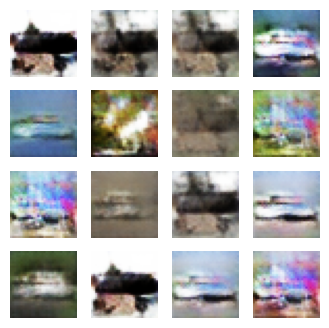

(32, 32, 3)
  Channel stats: Red=0.532/0.243  Green=0.531/0.248  Blue=0.525/0.278  
Epoch 39/200  gen_loss=4.652  disc_loss=0.367  time=6.6s


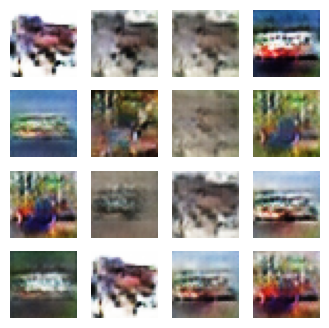

(32, 32, 3)
  Channel stats: Red=0.487/0.225  Green=0.470/0.228  Blue=0.451/0.237  
Epoch 40/200  gen_loss=4.867  disc_loss=0.235  time=6.6s


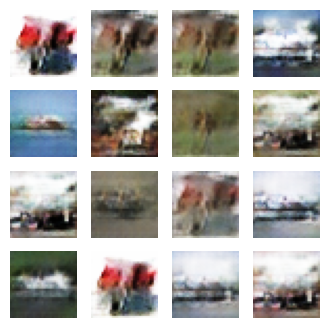

(32, 32, 3)
  Channel stats: Red=0.540/0.253  Green=0.531/0.255  Blue=0.512/0.278  
Epoch 41/200  gen_loss=3.613  disc_loss=0.441  time=6.5s


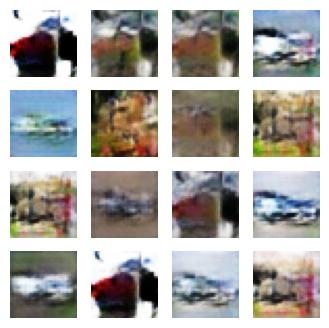

(32, 32, 3)
  Channel stats: Red=0.513/0.242  Green=0.499/0.253  Blue=0.476/0.282  
Epoch 42/200  gen_loss=2.532  disc_loss=0.798  time=6.7s


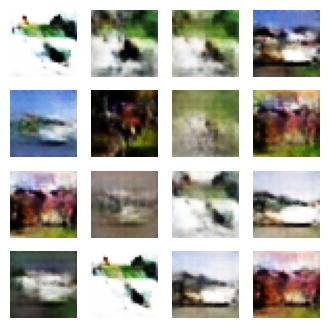

(32, 32, 3)
  Channel stats: Red=0.531/0.288  Green=0.527/0.291  Blue=0.485/0.324  
Epoch 43/200  gen_loss=3.662  disc_loss=0.304  time=6.6s


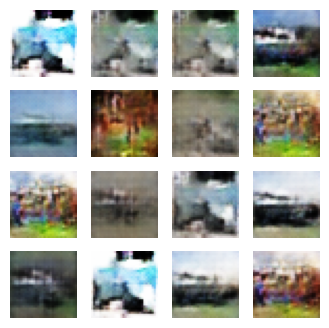

(32, 32, 3)
  Channel stats: Red=0.494/0.237  Green=0.509/0.249  Blue=0.476/0.277  
Epoch 44/200  gen_loss=3.882  disc_loss=0.824  time=6.7s


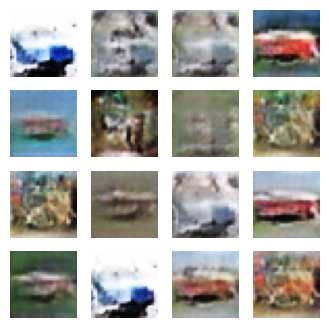

(32, 32, 3)
  Channel stats: Red=0.529/0.225  Green=0.525/0.220  Blue=0.504/0.245  
Epoch 45/200  gen_loss=2.336  disc_loss=0.434  time=6.5s


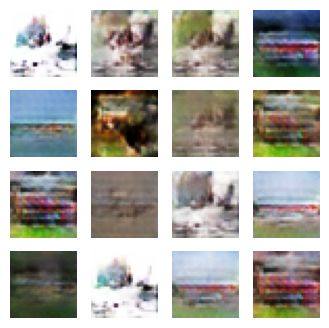

(32, 32, 3)
  Channel stats: Red=0.536/0.235  Green=0.530/0.240  Blue=0.496/0.273  
Epoch 46/200  gen_loss=4.260  disc_loss=0.260  time=6.7s


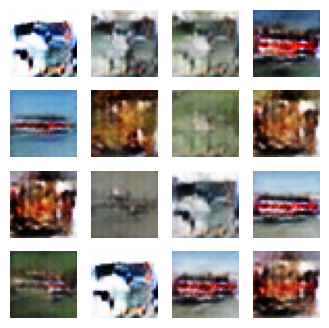

(32, 32, 3)
  Channel stats: Red=0.481/0.248  Green=0.458/0.257  Blue=0.443/0.282  
Epoch 47/200  gen_loss=3.783  disc_loss=0.216  time=6.6s


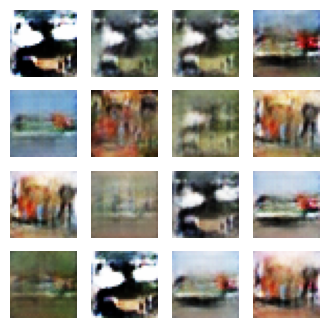

(32, 32, 3)
  Channel stats: Red=0.490/0.243  Green=0.475/0.240  Blue=0.435/0.261  
Epoch 48/200  gen_loss=4.531  disc_loss=0.292  time=6.6s


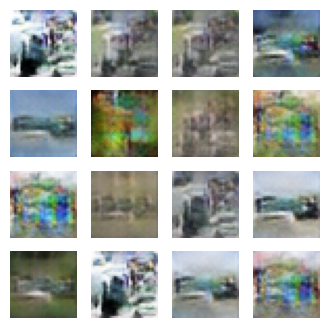

(32, 32, 3)
  Channel stats: Red=0.495/0.181  Green=0.525/0.177  Blue=0.498/0.209  
Epoch 49/200  gen_loss=3.209  disc_loss=0.230  time=6.7s


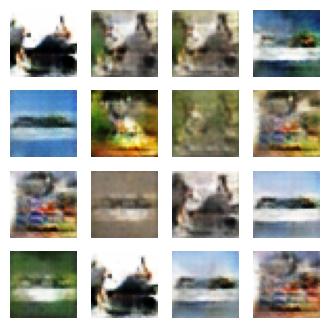

(32, 32, 3)
  Channel stats: Red=0.502/0.251  Green=0.507/0.240  Blue=0.463/0.274  
Epoch 50/200  gen_loss=3.263  disc_loss=0.188  time=6.6s


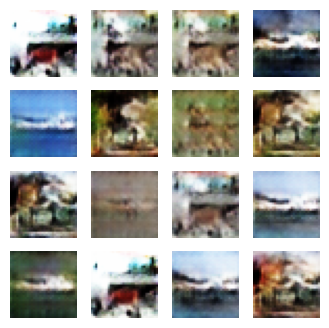

(32, 32, 3)
  Channel stats: Red=0.493/0.256  Green=0.494/0.258  Blue=0.469/0.284  
Epoch 51/200  gen_loss=3.811  disc_loss=0.215  time=6.9s


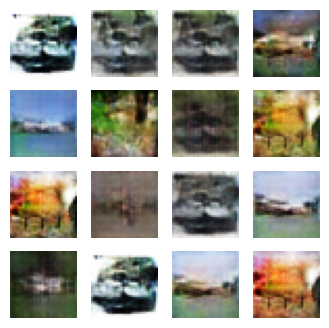

(32, 32, 3)
  Channel stats: Red=0.471/0.246  Green=0.465/0.231  Blue=0.415/0.265  
Epoch 52/200  gen_loss=3.232  disc_loss=0.283  time=6.6s


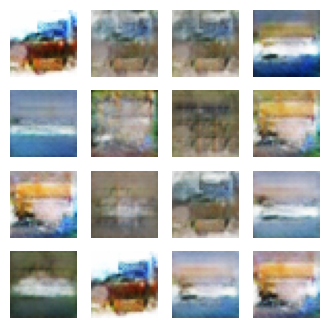

(32, 32, 3)
  Channel stats: Red=0.554/0.209  Green=0.557/0.188  Blue=0.536/0.218  
Epoch 53/200  gen_loss=6.308  disc_loss=0.910  time=6.8s


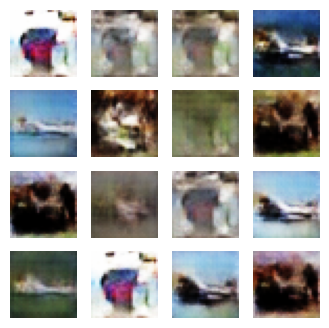

(32, 32, 3)
  Channel stats: Red=0.467/0.251  Green=0.463/0.266  Blue=0.451/0.287  
Epoch 54/200  gen_loss=2.611  disc_loss=0.414  time=6.6s


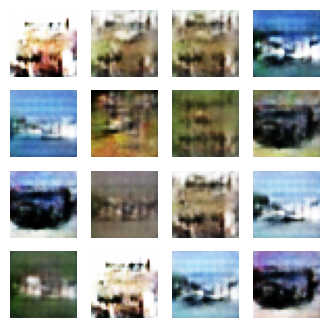

(32, 32, 3)
  Channel stats: Red=0.493/0.268  Green=0.513/0.265  Blue=0.498/0.304  
Epoch 55/200  gen_loss=4.127  disc_loss=0.295  time=6.8s


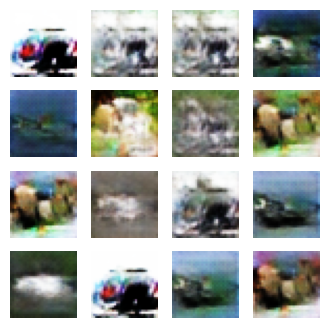

(32, 32, 3)
  Channel stats: Red=0.480/0.284  Green=0.502/0.274  Blue=0.480/0.288  
Epoch 56/200  gen_loss=2.095  disc_loss=0.622  time=6.6s


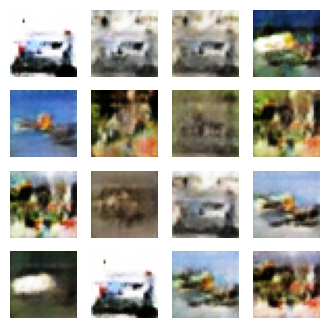

(32, 32, 3)
  Channel stats: Red=0.512/0.270  Green=0.507/0.264  Blue=0.468/0.293  
Epoch 57/200  gen_loss=2.608  disc_loss=0.516  time=6.8s


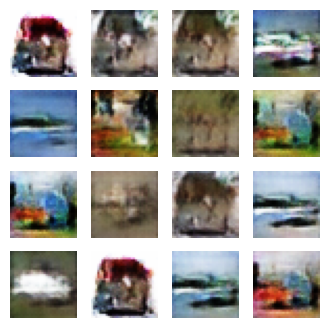

(32, 32, 3)
  Channel stats: Red=0.474/0.232  Green=0.468/0.237  Blue=0.444/0.273  
Epoch 58/200  gen_loss=2.387  disc_loss=0.639  time=6.7s


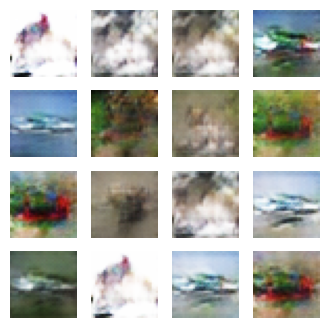

(32, 32, 3)
  Channel stats: Red=0.566/0.235  Green=0.575/0.231  Blue=0.542/0.270  
Epoch 59/200  gen_loss=3.349  disc_loss=0.297  time=6.5s


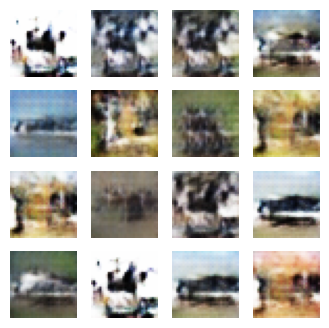

(32, 32, 3)
  Channel stats: Red=0.543/0.262  Green=0.531/0.257  Blue=0.493/0.267  
Epoch 60/200  gen_loss=4.094  disc_loss=0.164  time=6.7s


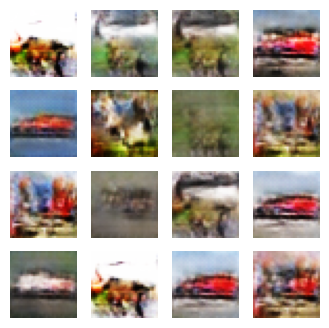

(32, 32, 3)
  Channel stats: Red=0.549/0.226  Green=0.496/0.234  Blue=0.450/0.264  
Epoch 61/200  gen_loss=3.836  disc_loss=0.202  time=6.5s


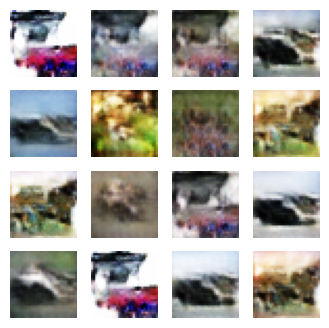

(32, 32, 3)
  Channel stats: Red=0.524/0.260  Green=0.506/0.263  Blue=0.473/0.276  
Epoch 62/200  gen_loss=6.940  disc_loss=0.996  time=6.7s


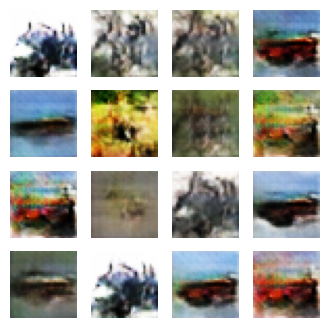

(32, 32, 3)
  Channel stats: Red=0.480/0.240  Green=0.478/0.247  Blue=0.438/0.279  
Epoch 63/200  gen_loss=2.836  disc_loss=0.277  time=6.5s


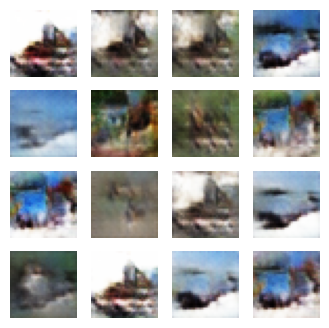

(32, 32, 3)
  Channel stats: Red=0.498/0.250  Green=0.512/0.249  Blue=0.518/0.273  
Epoch 64/200  gen_loss=2.979  disc_loss=0.191  time=6.7s


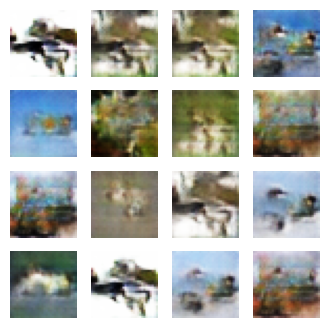

(32, 32, 3)
  Channel stats: Red=0.540/0.227  Green=0.555/0.229  Blue=0.523/0.277  
Epoch 65/200  gen_loss=4.826  disc_loss=0.713  time=6.6s


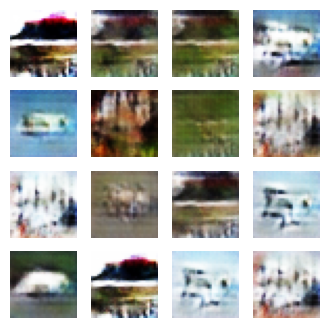

(32, 32, 3)
  Channel stats: Red=0.527/0.264  Green=0.535/0.274  Blue=0.509/0.312  
Epoch 66/200  gen_loss=3.633  disc_loss=0.220  time=6.7s


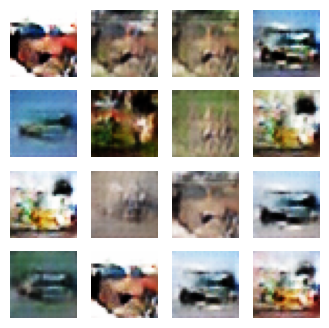

(32, 32, 3)
  Channel stats: Red=0.512/0.257  Green=0.503/0.251  Blue=0.474/0.276  
Epoch 67/200  gen_loss=3.313  disc_loss=0.252  time=6.7s


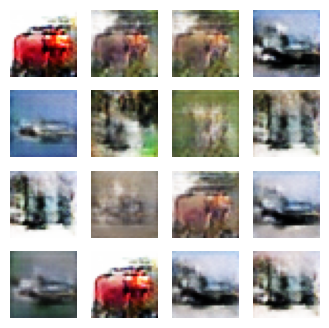

(32, 32, 3)
  Channel stats: Red=0.523/0.248  Green=0.505/0.251  Blue=0.491/0.270  
Epoch 68/200  gen_loss=3.490  disc_loss=0.410  time=6.6s


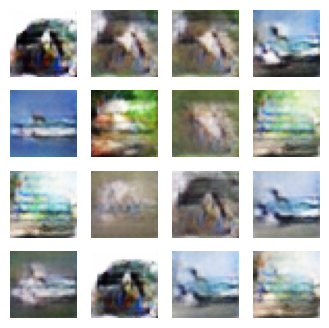

(32, 32, 3)
  Channel stats: Red=0.526/0.222  Green=0.549/0.225  Blue=0.540/0.245  
Epoch 69/200  gen_loss=3.745  disc_loss=0.288  time=6.7s


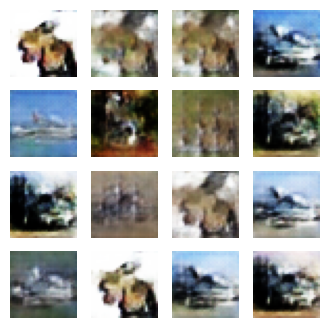

(32, 32, 3)
  Channel stats: Red=0.488/0.268  Green=0.496/0.271  Blue=0.480/0.299  
Epoch 70/200  gen_loss=3.444  disc_loss=0.399  time=6.6s


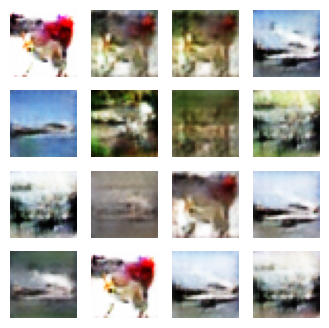

(32, 32, 3)
  Channel stats: Red=0.562/0.262  Green=0.557/0.270  Blue=0.532/0.298  
Epoch 71/200  gen_loss=3.530  disc_loss=0.478  time=6.7s


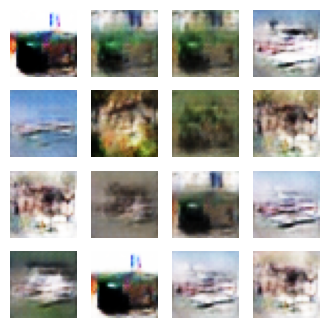

(32, 32, 3)
  Channel stats: Red=0.545/0.262  Green=0.542/0.255  Blue=0.518/0.284  
Epoch 72/200  gen_loss=3.078  disc_loss=0.322  time=6.5s


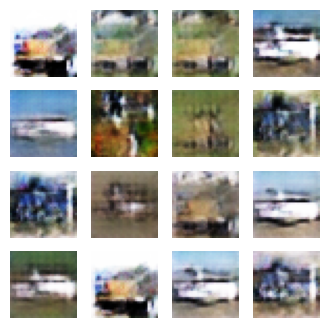

(32, 32, 3)
  Channel stats: Red=0.515/0.236  Green=0.516/0.234  Blue=0.490/0.266  
Epoch 73/200  gen_loss=2.361  disc_loss=0.975  time=6.7s


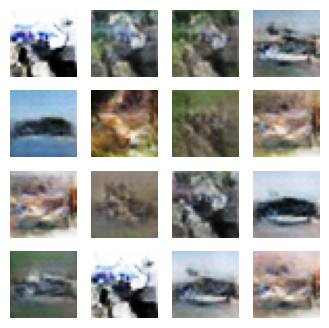

(32, 32, 3)
  Channel stats: Red=0.496/0.230  Green=0.500/0.227  Blue=0.486/0.250  
Epoch 74/200  gen_loss=3.040  disc_loss=0.433  time=6.6s


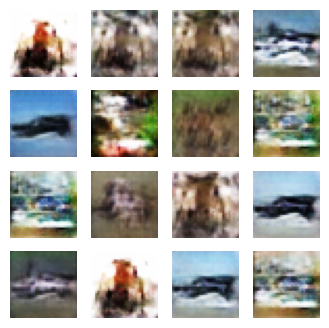

(32, 32, 3)
  Channel stats: Red=0.524/0.242  Green=0.524/0.245  Blue=0.496/0.276  
Epoch 75/200  gen_loss=3.890  disc_loss=0.587  time=6.8s


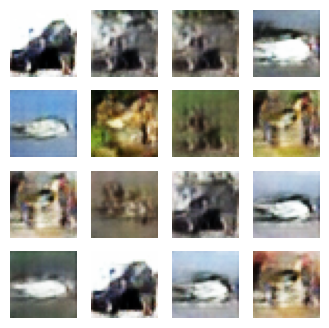

(32, 32, 3)
  Channel stats: Red=0.513/0.241  Green=0.509/0.243  Blue=0.472/0.266  
Epoch 76/200  gen_loss=3.957  disc_loss=0.306  time=6.6s


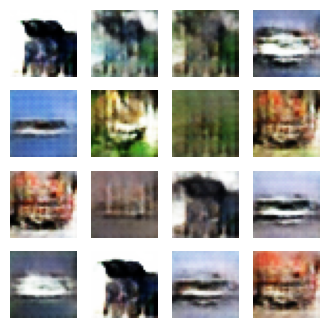

(32, 32, 3)
  Channel stats: Red=0.481/0.273  Green=0.472/0.261  Blue=0.450/0.289  
Epoch 77/200  gen_loss=2.714  disc_loss=0.515  time=6.7s


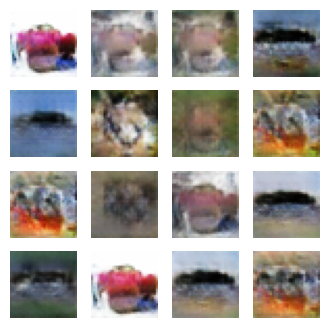

(32, 32, 3)
  Channel stats: Red=0.511/0.217  Green=0.480/0.207  Blue=0.463/0.233  
Epoch 78/200  gen_loss=4.145  disc_loss=0.351  time=6.7s


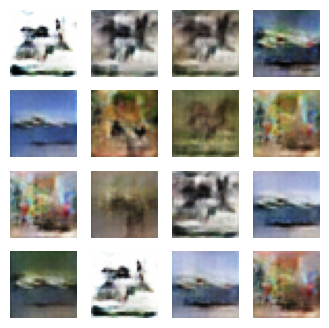

(32, 32, 3)
  Channel stats: Red=0.508/0.229  Green=0.504/0.223  Blue=0.483/0.250  
Epoch 79/200  gen_loss=4.410  disc_loss=0.122  time=6.5s


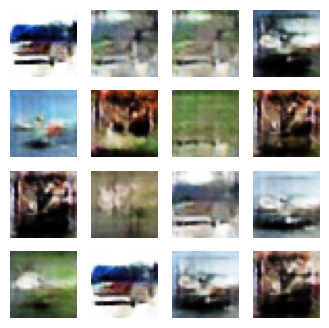

(32, 32, 3)
  Channel stats: Red=0.473/0.271  Green=0.482/0.277  Blue=0.454/0.291  
Epoch 80/200  gen_loss=3.841  disc_loss=0.170  time=6.7s


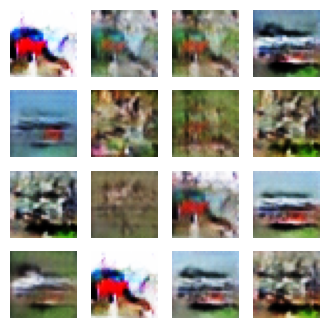

(32, 32, 3)
  Channel stats: Red=0.480/0.228  Green=0.475/0.234  Blue=0.436/0.268  
Epoch 81/200  gen_loss=3.687  disc_loss=0.196  time=6.6s


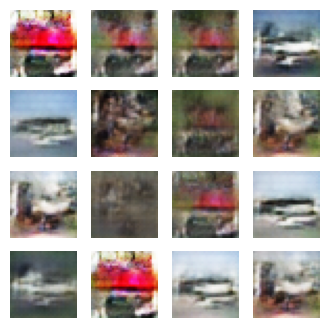

(32, 32, 3)
  Channel stats: Red=0.505/0.212  Green=0.462/0.219  Blue=0.444/0.235  
Epoch 82/200  gen_loss=5.037  disc_loss=0.395  time=6.7s


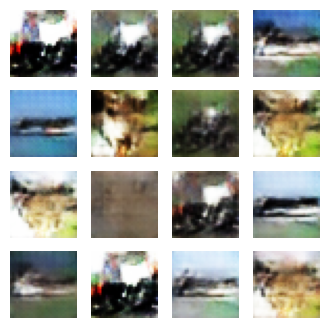

(32, 32, 3)
  Channel stats: Red=0.480/0.282  Green=0.490/0.281  Blue=0.446/0.294  
Epoch 83/200  gen_loss=3.768  disc_loss=0.478  time=6.6s


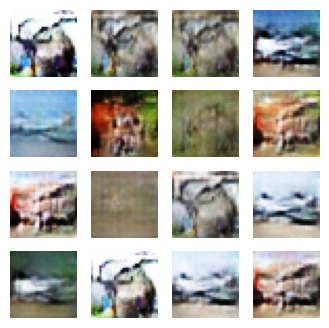

(32, 32, 3)
  Channel stats: Red=0.544/0.242  Green=0.541/0.243  Blue=0.512/0.275  
Epoch 84/200  gen_loss=4.363  disc_loss=0.433  time=6.8s


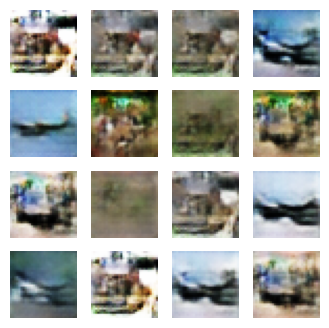

(32, 32, 3)
  Channel stats: Red=0.498/0.229  Green=0.512/0.227  Blue=0.482/0.260  
Epoch 85/200  gen_loss=3.290  disc_loss=0.230  time=6.7s


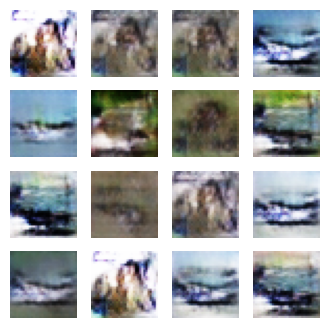

(32, 32, 3)
  Channel stats: Red=0.490/0.232  Green=0.507/0.234  Blue=0.514/0.258  
Epoch 86/200  gen_loss=4.866  disc_loss=0.204  time=6.7s


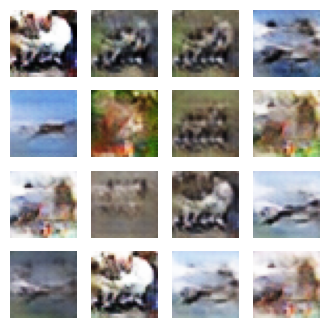

(32, 32, 3)
  Channel stats: Red=0.515/0.220  Green=0.505/0.225  Blue=0.499/0.255  
Epoch 87/200  gen_loss=4.310  disc_loss=0.228  time=6.7s


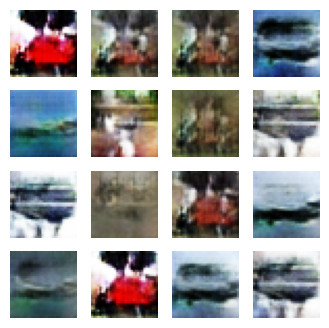

(32, 32, 3)
  Channel stats: Red=0.441/0.264  Green=0.439/0.262  Blue=0.441/0.280  
Epoch 88/200  gen_loss=2.971  disc_loss=0.312  time=6.6s


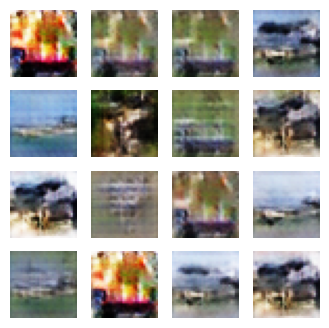

(32, 32, 3)
  Channel stats: Red=0.494/0.224  Green=0.480/0.215  Blue=0.448/0.241  
Epoch 89/200  gen_loss=3.448  disc_loss=0.253  time=6.7s


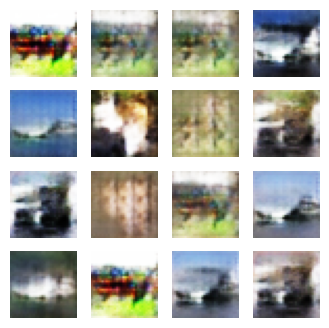

(32, 32, 3)
  Channel stats: Red=0.542/0.255  Green=0.549/0.255  Blue=0.509/0.260  
Epoch 90/200  gen_loss=4.268  disc_loss=0.376  time=6.6s


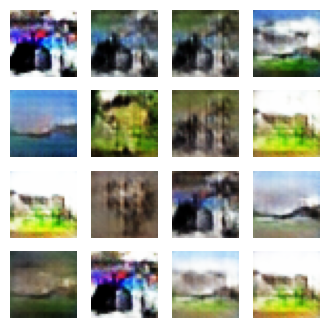

(32, 32, 3)
  Channel stats: Red=0.491/0.277  Green=0.512/0.278  Blue=0.454/0.306  
Epoch 91/200  gen_loss=3.366  disc_loss=0.334  time=6.9s


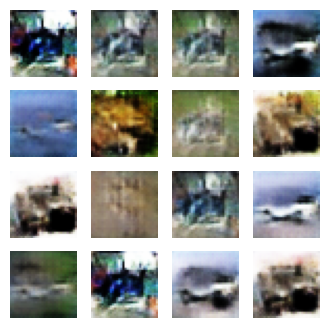

(32, 32, 3)
  Channel stats: Red=0.448/0.251  Green=0.461/0.241  Blue=0.442/0.262  
Epoch 92/200  gen_loss=4.324  disc_loss=0.182  time=6.7s


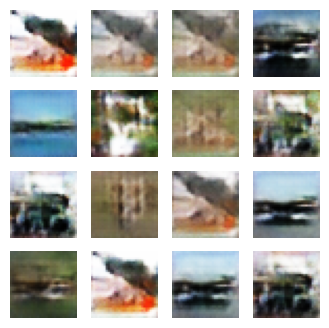

(32, 32, 3)
  Channel stats: Red=0.521/0.255  Green=0.515/0.245  Blue=0.477/0.271  
Epoch 93/200  gen_loss=3.556  disc_loss=0.372  time=6.8s


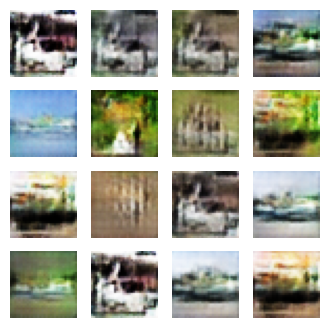

(32, 32, 3)
  Channel stats: Red=0.509/0.237  Green=0.516/0.238  Blue=0.445/0.267  
Epoch 94/200  gen_loss=3.195  disc_loss=0.327  time=6.7s


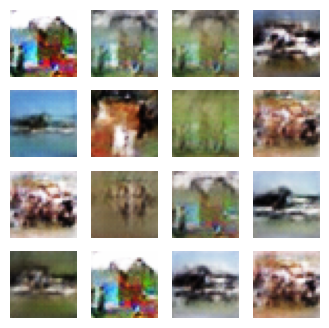

(32, 32, 3)
  Channel stats: Red=0.506/0.210  Green=0.495/0.215  Blue=0.443/0.247  
Epoch 95/200  gen_loss=3.073  disc_loss=0.282  time=6.7s


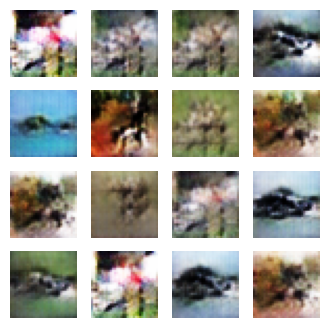

(32, 32, 3)
  Channel stats: Red=0.489/0.231  Green=0.485/0.231  Blue=0.444/0.262  
Epoch 96/200  gen_loss=2.969  disc_loss=0.484  time=6.7s


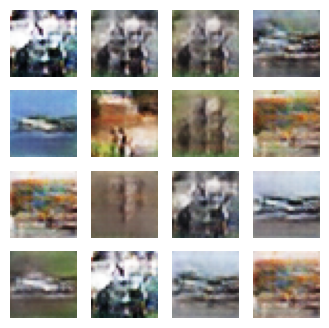

(32, 32, 3)
  Channel stats: Red=0.504/0.209  Green=0.488/0.206  Blue=0.464/0.225  
Epoch 97/200  gen_loss=5.551  disc_loss=0.289  time=6.5s


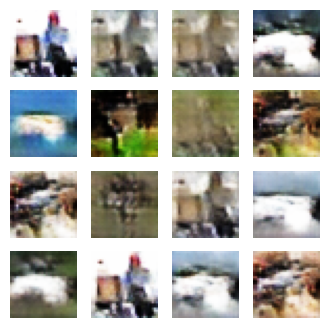

(32, 32, 3)
  Channel stats: Red=0.530/0.270  Green=0.522/0.264  Blue=0.483/0.288  
Epoch 98/200  gen_loss=4.147  disc_loss=0.257  time=6.7s


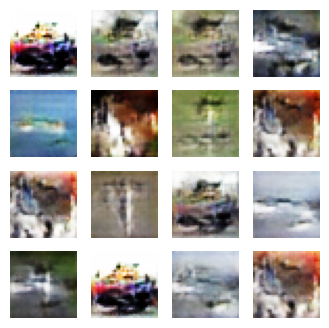

(32, 32, 3)
  Channel stats: Red=0.535/0.244  Green=0.519/0.248  Blue=0.495/0.263  
Epoch 99/200  gen_loss=2.023  disc_loss=0.602  time=6.5s


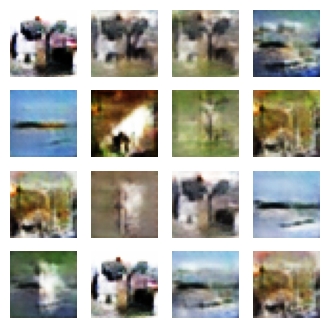

(32, 32, 3)
  Channel stats: Red=0.518/0.224  Green=0.520/0.228  Blue=0.477/0.266  
Epoch 100/200  gen_loss=3.329  disc_loss=0.243  time=6.6s


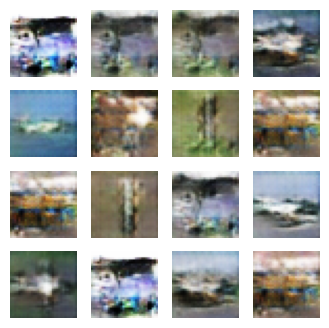

(32, 32, 3)
  Channel stats: Red=0.487/0.213  Green=0.500/0.207  Blue=0.477/0.237  
Epoch 101/200  gen_loss=3.524  disc_loss=0.302  time=6.5s


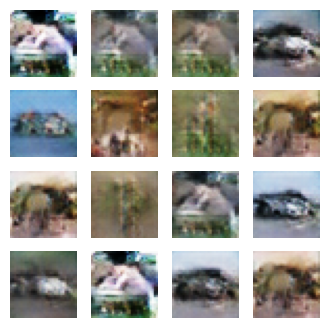

(32, 32, 3)
  Channel stats: Red=0.480/0.200  Green=0.475/0.195  Blue=0.445/0.225  
Epoch 102/200  gen_loss=2.555  disc_loss=0.294  time=6.7s


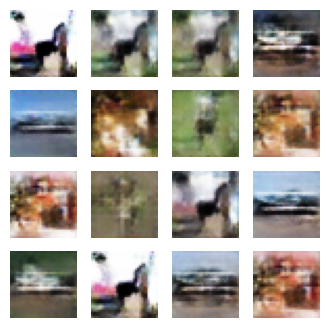

(32, 32, 3)
  Channel stats: Red=0.527/0.237  Green=0.497/0.233  Blue=0.459/0.259  
Epoch 103/200  gen_loss=2.618  disc_loss=0.496  time=6.6s


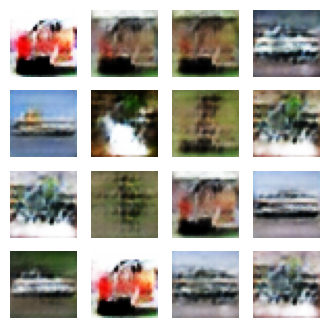

(32, 32, 3)
  Channel stats: Red=0.498/0.264  Green=0.483/0.254  Blue=0.450/0.286  
Epoch 104/200  gen_loss=3.454  disc_loss=0.202  time=6.7s


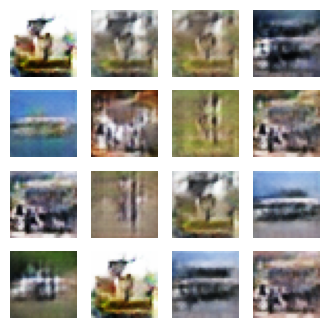

(32, 32, 3)
  Channel stats: Red=0.502/0.217  Green=0.493/0.208  Blue=0.463/0.234  
Epoch 105/200  gen_loss=3.246  disc_loss=0.353  time=6.6s


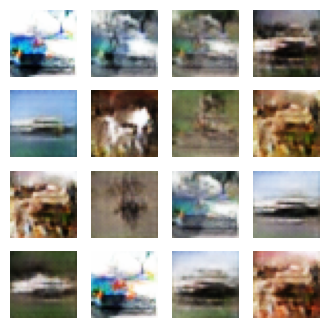

(32, 32, 3)
  Channel stats: Red=0.513/0.250  Green=0.497/0.248  Blue=0.463/0.279  
Epoch 106/200  gen_loss=3.444  disc_loss=0.201  time=6.5s


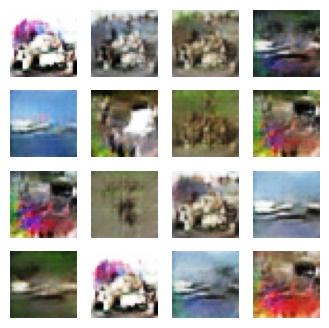

(32, 32, 3)
  Channel stats: Red=0.493/0.228  Green=0.479/0.228  Blue=0.450/0.260  
Epoch 107/200  gen_loss=3.893  disc_loss=0.319  time=6.7s


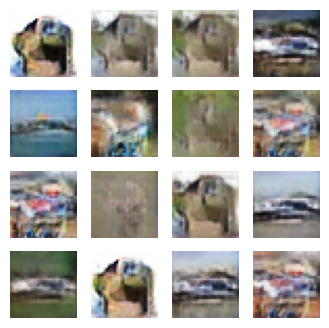

(32, 32, 3)
  Channel stats: Red=0.524/0.202  Green=0.514/0.195  Blue=0.484/0.218  
Epoch 108/200  gen_loss=3.727  disc_loss=0.262  time=6.5s


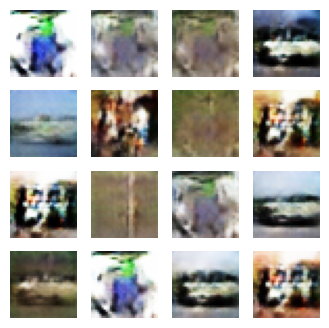

(32, 32, 3)
  Channel stats: Red=0.512/0.257  Green=0.504/0.259  Blue=0.471/0.278  
Epoch 109/200  gen_loss=4.320  disc_loss=0.345  time=6.8s


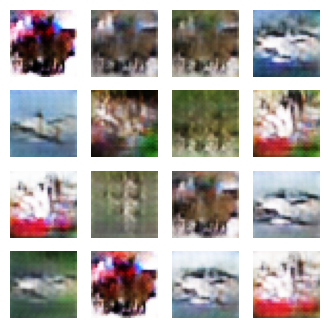

(32, 32, 3)
  Channel stats: Red=0.529/0.247  Green=0.498/0.252  Blue=0.485/0.279  
Epoch 110/200  gen_loss=4.098  disc_loss=0.318  time=6.6s


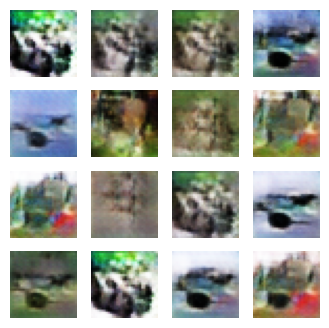

(32, 32, 3)
  Channel stats: Red=0.468/0.226  Green=0.489/0.224  Blue=0.450/0.252  
Epoch 111/200  gen_loss=4.767  disc_loss=0.183  time=6.8s


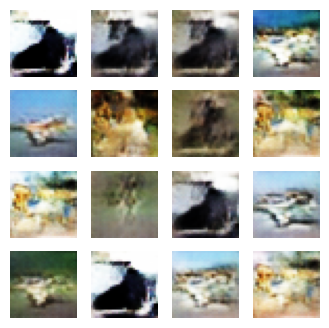

(32, 32, 3)
  Channel stats: Red=0.523/0.281  Green=0.528/0.276  Blue=0.481/0.287  
Epoch 112/200  gen_loss=5.038  disc_loss=0.154  time=6.6s


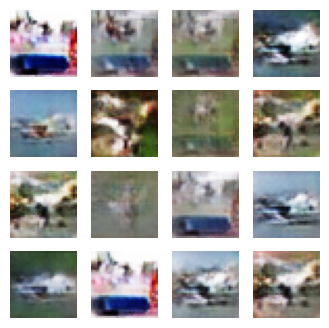

(32, 32, 3)
  Channel stats: Red=0.503/0.218  Green=0.507/0.206  Blue=0.497/0.226  
Epoch 113/200  gen_loss=4.530  disc_loss=0.246  time=6.8s


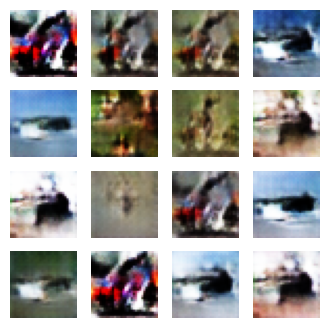

(32, 32, 3)
  Channel stats: Red=0.464/0.264  Green=0.458/0.268  Blue=0.450/0.297  
Epoch 114/200  gen_loss=4.656  disc_loss=0.509  time=6.7s


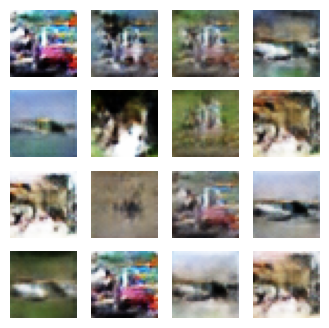

(32, 32, 3)
  Channel stats: Red=0.489/0.223  Green=0.486/0.221  Blue=0.456/0.244  
Epoch 115/200  gen_loss=3.916  disc_loss=0.261  time=6.7s


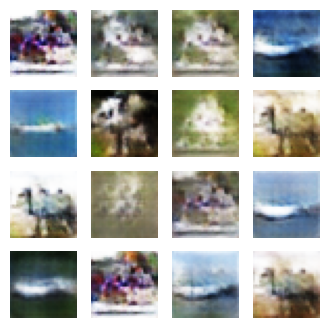

(32, 32, 3)
  Channel stats: Red=0.523/0.254  Green=0.539/0.242  Blue=0.526/0.263  
Epoch 116/200  gen_loss=3.587  disc_loss=0.301  time=6.7s


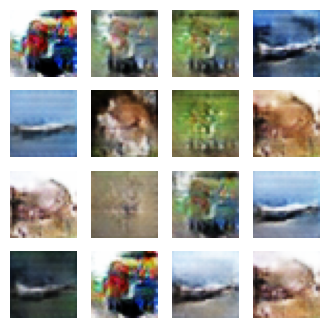

(32, 32, 3)
  Channel stats: Red=0.491/0.243  Green=0.496/0.235  Blue=0.467/0.259  
Epoch 117/200  gen_loss=4.033  disc_loss=0.478  time=6.6s


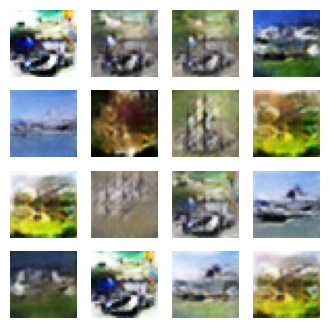

(32, 32, 3)
  Channel stats: Red=0.490/0.225  Green=0.510/0.223  Blue=0.454/0.267  
Epoch 118/200  gen_loss=4.450  disc_loss=0.495  time=6.7s


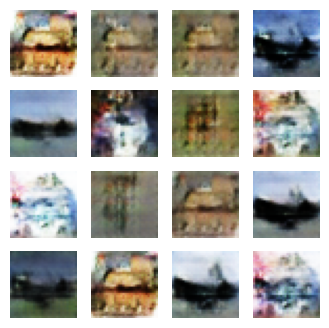

(32, 32, 3)
  Channel stats: Red=0.500/0.242  Green=0.492/0.234  Blue=0.460/0.262  
Epoch 119/200  gen_loss=6.084  disc_loss=0.571  time=6.6s


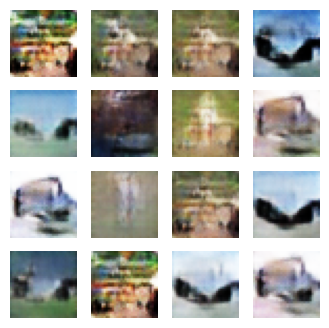

(32, 32, 3)
  Channel stats: Red=0.533/0.234  Green=0.534/0.229  Blue=0.499/0.259  
Epoch 120/200  gen_loss=4.241  disc_loss=0.132  time=6.7s


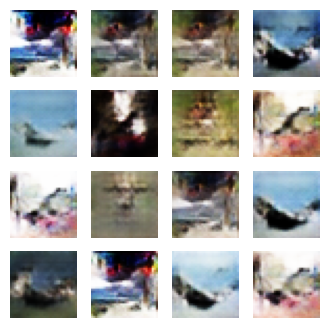

(32, 32, 3)
  Channel stats: Red=0.509/0.269  Green=0.508/0.270  Blue=0.497/0.283  
Epoch 121/200  gen_loss=4.211  disc_loss=0.188  time=10.2s


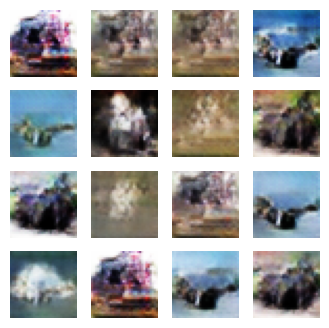

(32, 32, 3)
  Channel stats: Red=0.467/0.224  Green=0.468/0.226  Blue=0.470/0.251  
Epoch 122/200  gen_loss=4.453  disc_loss=0.356  time=6.6s


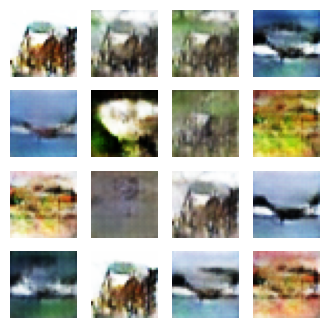

(32, 32, 3)
  Channel stats: Red=0.524/0.260  Green=0.531/0.247  Blue=0.481/0.277  
Epoch 123/200  gen_loss=3.410  disc_loss=0.392  time=6.8s


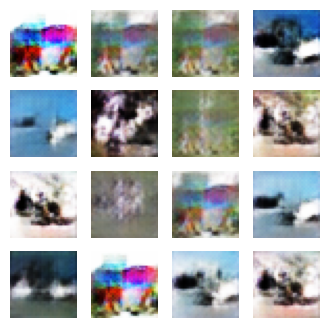

(32, 32, 3)
  Channel stats: Red=0.535/0.258  Green=0.553/0.249  Blue=0.565/0.268  
Epoch 124/200  gen_loss=4.699  disc_loss=0.169  time=6.6s


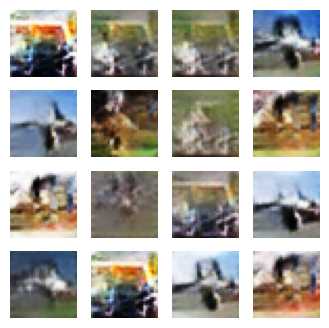

(32, 32, 3)
  Channel stats: Red=0.506/0.229  Green=0.490/0.221  Blue=0.451/0.246  
Epoch 125/200  gen_loss=5.820  disc_loss=0.642  time=6.9s


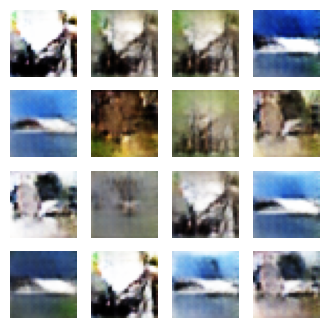

(32, 32, 3)
  Channel stats: Red=0.481/0.274  Green=0.502/0.264  Blue=0.515/0.283  
Epoch 126/200  gen_loss=4.151  disc_loss=0.188  time=6.8s


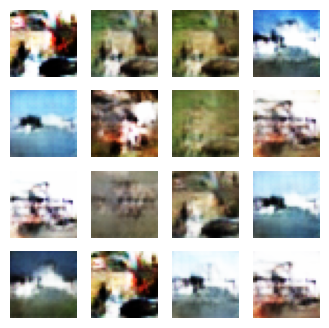

(32, 32, 3)
  Channel stats: Red=0.540/0.279  Green=0.548/0.282  Blue=0.515/0.317  
Epoch 127/200  gen_loss=4.971  disc_loss=0.217  time=6.6s


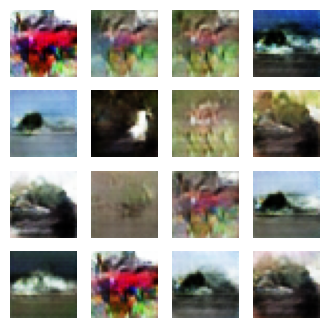

(32, 32, 3)
  Channel stats: Red=0.428/0.242  Green=0.418/0.252  Blue=0.381/0.256  
Epoch 128/200  gen_loss=4.531  disc_loss=0.232  time=6.8s


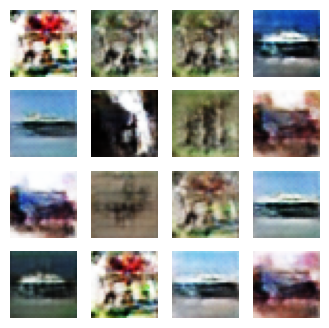

(32, 32, 3)
  Channel stats: Red=0.472/0.257  Green=0.476/0.256  Blue=0.462/0.272  
Epoch 129/200  gen_loss=2.304  disc_loss=0.557  time=6.6s


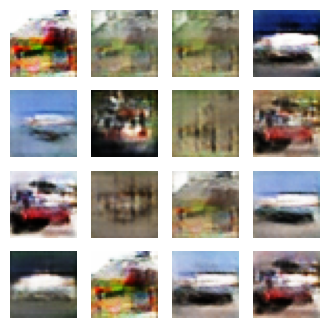

(32, 32, 3)
  Channel stats: Red=0.502/0.234  Green=0.478/0.233  Blue=0.442/0.258  
Epoch 130/200  gen_loss=3.251  disc_loss=0.241  time=6.8s


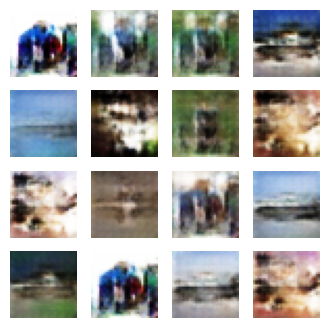

(32, 32, 3)
  Channel stats: Red=0.509/0.263  Green=0.510/0.254  Blue=0.494/0.273  
Epoch 131/200  gen_loss=4.639  disc_loss=0.238  time=6.5s


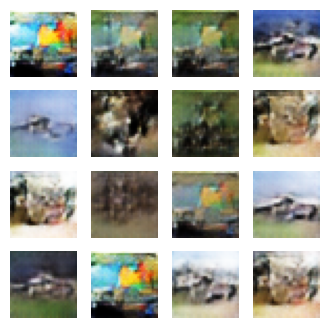

(32, 32, 3)
  Channel stats: Red=0.482/0.243  Green=0.489/0.241  Blue=0.438/0.259  
Epoch 132/200  gen_loss=4.407  disc_loss=0.236  time=6.9s


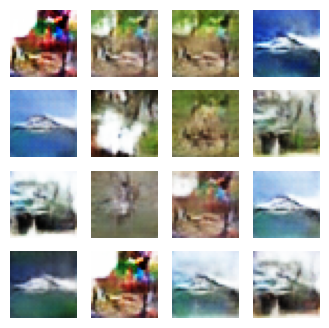

(32, 32, 3)
  Channel stats: Red=0.523/0.248  Green=0.538/0.240  Blue=0.514/0.274  
Epoch 133/200  gen_loss=3.676  disc_loss=0.295  time=6.7s


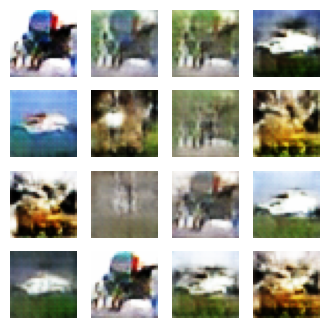

(32, 32, 3)
  Channel stats: Red=0.507/0.268  Green=0.512/0.261  Blue=0.459/0.300  
Epoch 134/200  gen_loss=3.082  disc_loss=0.420  time=6.8s


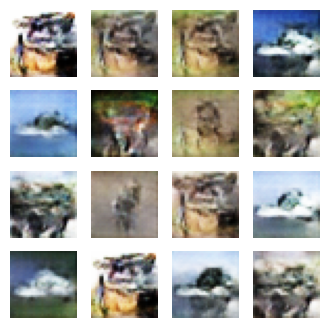

(32, 32, 3)
  Channel stats: Red=0.517/0.239  Green=0.519/0.233  Blue=0.491/0.255  
Epoch 135/200  gen_loss=2.706  disc_loss=0.343  time=10.2s


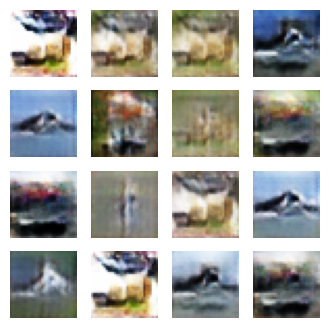

(32, 32, 3)
  Channel stats: Red=0.504/0.237  Green=0.507/0.226  Blue=0.487/0.242  
Epoch 136/200  gen_loss=4.147  disc_loss=0.342  time=6.6s


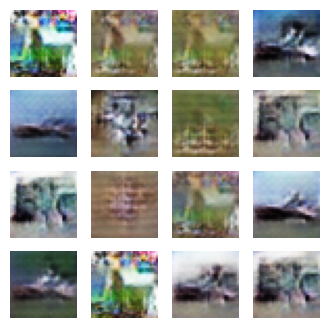

(32, 32, 3)
  Channel stats: Red=0.471/0.193  Green=0.485/0.192  Blue=0.459/0.219  
Epoch 137/200  gen_loss=3.690  disc_loss=0.488  time=7.4s


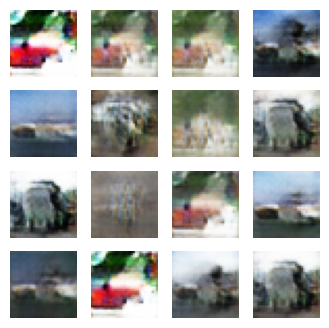

(32, 32, 3)
  Channel stats: Red=0.499/0.258  Green=0.509/0.252  Blue=0.494/0.265  
Epoch 138/200  gen_loss=3.424  disc_loss=0.342  time=6.8s


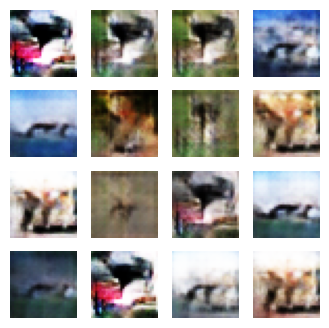

(32, 32, 3)
  Channel stats: Red=0.506/0.284  Green=0.493/0.271  Blue=0.477/0.292  
Epoch 139/200  gen_loss=6.429  disc_loss=0.022  time=6.7s


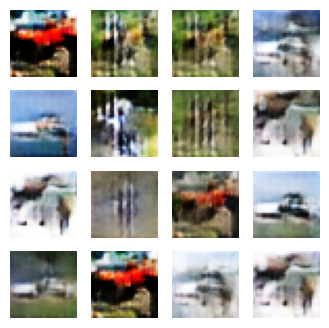

(32, 32, 3)
  Channel stats: Red=0.508/0.257  Green=0.508/0.257  Blue=0.469/0.294  
Epoch 140/200  gen_loss=3.302  disc_loss=0.333  time=6.8s


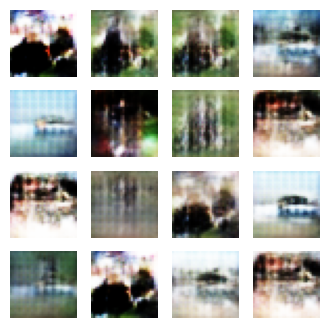

(32, 32, 3)
  Channel stats: Red=0.514/0.298  Green=0.524/0.298  Blue=0.490/0.309  
Epoch 141/200  gen_loss=3.522  disc_loss=0.165  time=6.6s


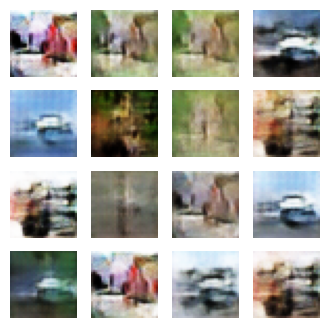

(32, 32, 3)
  Channel stats: Red=0.524/0.240  Green=0.522/0.237  Blue=0.485/0.268  
Epoch 142/200  gen_loss=3.132  disc_loss=0.318  time=6.8s


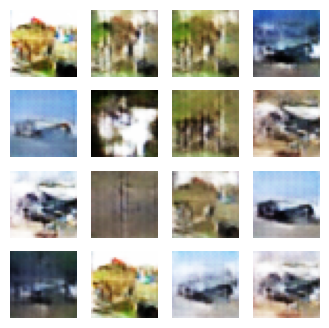

(32, 32, 3)
  Channel stats: Red=0.556/0.248  Green=0.557/0.245  Blue=0.517/0.281  
Epoch 143/200  gen_loss=2.929  disc_loss=0.305  time=6.7s


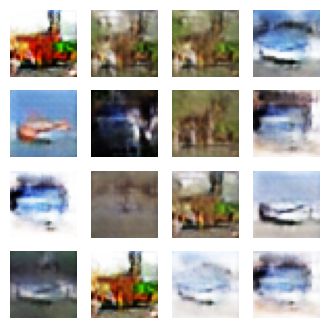

(32, 32, 3)
  Channel stats: Red=0.547/0.252  Green=0.539/0.261  Blue=0.524/0.305  
Epoch 144/200  gen_loss=4.015  disc_loss=0.261  time=6.8s


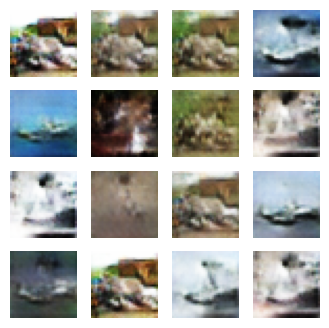

(32, 32, 3)
  Channel stats: Red=0.518/0.245  Green=0.523/0.251  Blue=0.496/0.279  
Epoch 145/200  gen_loss=4.052  disc_loss=0.364  time=7.2s


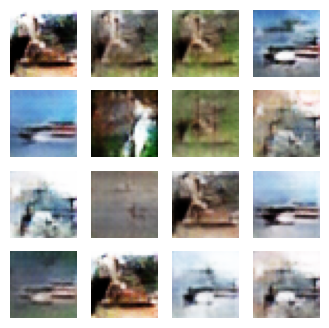

(32, 32, 3)
  Channel stats: Red=0.513/0.240  Green=0.519/0.242  Blue=0.503/0.274  
Epoch 146/200  gen_loss=5.661  disc_loss=0.417  time=6.7s


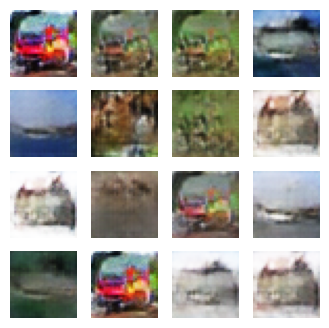

(32, 32, 3)
  Channel stats: Red=0.503/0.230  Green=0.490/0.226  Blue=0.457/0.250  
Epoch 147/200  gen_loss=4.305  disc_loss=0.255  time=6.8s


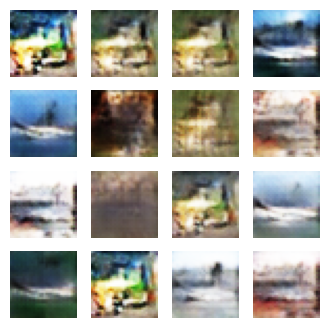

(32, 32, 3)
  Channel stats: Red=0.532/0.267  Green=0.529/0.250  Blue=0.493/0.264  
Epoch 148/200  gen_loss=3.634  disc_loss=0.399  time=6.6s


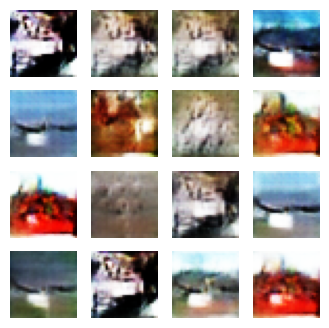

(32, 32, 3)
  Channel stats: Red=0.534/0.275  Green=0.484/0.288  Blue=0.464/0.312  
Epoch 149/200  gen_loss=3.608  disc_loss=0.246  time=6.8s


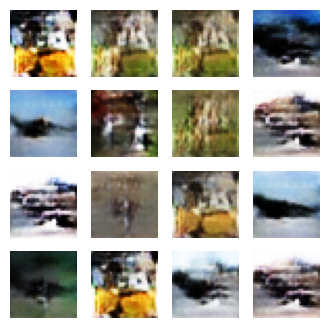

(32, 32, 3)
  Channel stats: Red=0.487/0.269  Green=0.477/0.263  Blue=0.430/0.293  
Epoch 150/200  gen_loss=4.891  disc_loss=0.294  time=6.6s


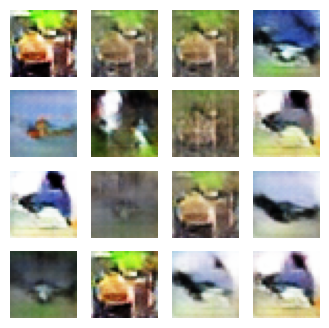

(32, 32, 3)
  Channel stats: Red=0.524/0.253  Green=0.531/0.254  Blue=0.466/0.262  
Epoch 151/200  gen_loss=4.762  disc_loss=0.412  time=6.8s


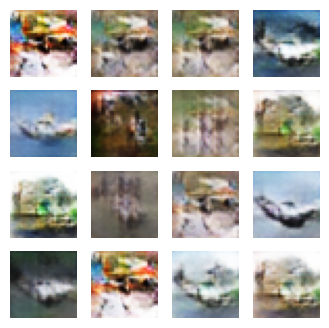

(32, 32, 3)
  Channel stats: Red=0.552/0.232  Green=0.542/0.225  Blue=0.512/0.252  
Epoch 152/200  gen_loss=3.478  disc_loss=0.333  time=6.6s


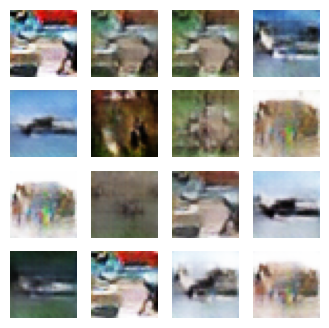

(32, 32, 3)
  Channel stats: Red=0.519/0.238  Green=0.521/0.239  Blue=0.504/0.271  
Epoch 153/200  gen_loss=4.956  disc_loss=0.258  time=6.8s


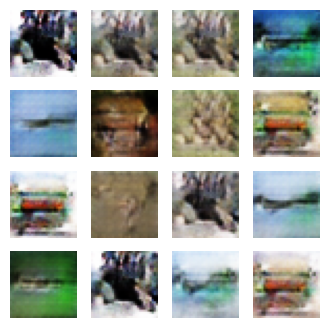

(32, 32, 3)
  Channel stats: Red=0.493/0.237  Green=0.514/0.231  Blue=0.480/0.262  
Epoch 154/200  gen_loss=4.710  disc_loss=0.590  time=6.6s


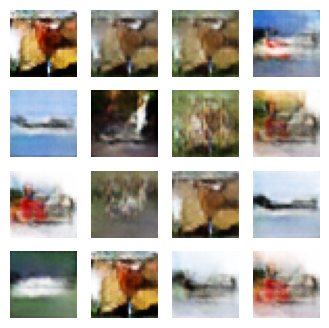

(32, 32, 3)
  Channel stats: Red=0.550/0.242  Green=0.527/0.249  Blue=0.480/0.295  
Epoch 155/200  gen_loss=4.408  disc_loss=0.329  time=6.7s


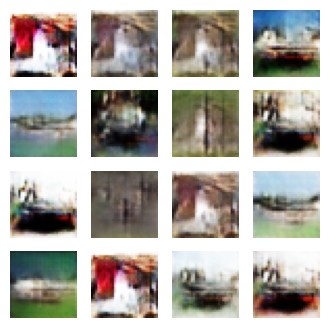

(32, 32, 3)
  Channel stats: Red=0.526/0.260  Green=0.506/0.267  Blue=0.471/0.282  
Epoch 156/200  gen_loss=2.615  disc_loss=0.436  time=6.6s


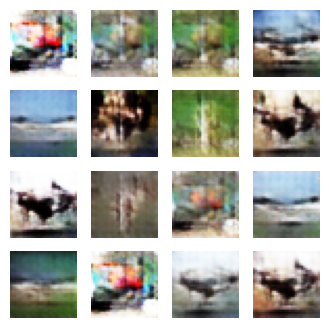

(32, 32, 3)
  Channel stats: Red=0.517/0.252  Green=0.523/0.250  Blue=0.480/0.273  
Epoch 157/200  gen_loss=3.093  disc_loss=0.383  time=6.5s


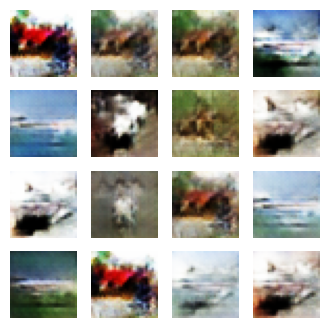

(32, 32, 3)
  Channel stats: Red=0.529/0.264  Green=0.528/0.271  Blue=0.496/0.298  
Epoch 158/200  gen_loss=2.368  disc_loss=0.463  time=6.7s


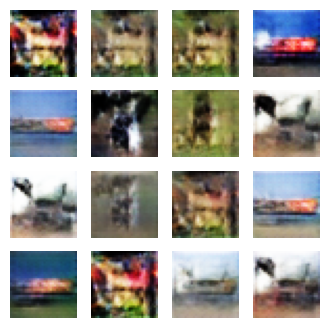

(32, 32, 3)
  Channel stats: Red=0.470/0.251  Green=0.454/0.238  Blue=0.425/0.264  
Epoch 159/200  gen_loss=2.872  disc_loss=0.273  time=6.6s


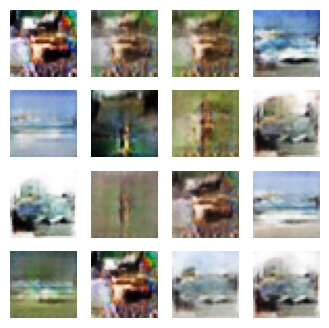

(32, 32, 3)
  Channel stats: Red=0.530/0.224  Green=0.534/0.226  Blue=0.497/0.259  
Epoch 160/200  gen_loss=4.528  disc_loss=0.251  time=6.7s


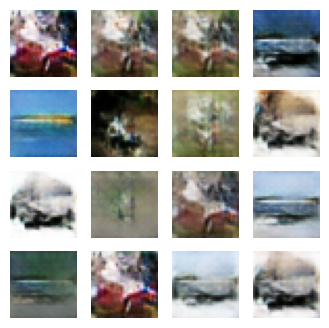

(32, 32, 3)
  Channel stats: Red=0.490/0.250  Green=0.497/0.246  Blue=0.486/0.267  
Epoch 161/200  gen_loss=3.479  disc_loss=0.212  time=6.6s


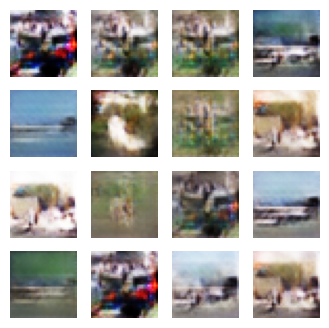

(32, 32, 3)
  Channel stats: Red=0.518/0.226  Green=0.507/0.217  Blue=0.483/0.234  


In [ ]:
# epoch stuff
epo = 200
# temp make epo 3 to see if graph method works

ga = []
da = []
epoz = [] #stores the epo
z = 1 #stores the current epoch


for epoch in range(epo):
  start = time.time() #for keeping track of time
  gena_loss = disc_loss = 0.0 #generator and discriminator loss intialization
  for image_batch in train_dataset:
    gena_loss, disc_loss = train_step(image_batch) #check the loss and train the function for each image batch
    ga.append(float(gena_loss))
    da.append(float(disc_loss))

  print(f"Epoch {epoch + 1}/{epo}  "
        f"gen_loss={float(gena_loss):.3f}  disc_loss={float(disc_loss):.3f}  "
        f"time={time.time() - start:.1f}s")
  if (epoch+1)%1 == 0: #if the epoch is divisible by 5, show the image
    generate_and_plot(generator, seed)
    predictions = generator(seed, training=False).numpy()
    images = predictions * 0.5 + 0.5
    channel_names = ["Red", "Green", "Blue"]
    print("  Channel stats:", end=" ")
    for c in range(3):
        print(f"{channel_names[c]}={images[:,:,:,c].mean():.3f}/{images[:,:,:,c].std():.3f}", end="  ")
    print()
  epoz.append(z)
  z+=1




In [13]:
#plotting

# print(ga, da)
# plt.plot(epoz,ga,label="Gen Error")
# plt.plot(epoz,da, label="Disc Error")
# plt.xlabel("Epochs")
# plt.axhline(1)

# plt.legend()

# plt.show()

#1 is true, so we are measuring the distance from 1 of the discriminator and generator error

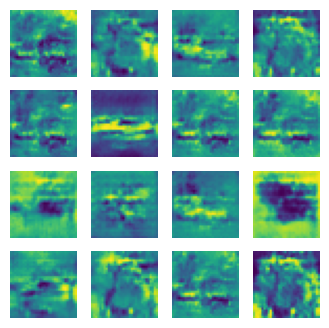

In [14]:
new_noise = tf.random.normal([16, latent_dim])
generate_and_plot(generator, new_noise)
